In [33]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import  LogisticRegression
from sklearn.ensemble import RandomForestClassifier

import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(284807, 31)


In [3]:
print("Duplicate Rows:")
print(df.duplicated().sum())

Duplicate Rows:
121


In [4]:
print("Dataset Shape:", df.shape)

print("Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (29799, 31)
Duplicate Rows: 121


In [5]:
df = pd.read_csv("creditcard.csv")

print("Original Dataset Shape:", df.shape)

print("Original Duplicate Rows:", df.duplicated().sum())

Original Dataset Shape: (284807, 31)
Original Duplicate Rows: 1081


In [6]:
df = df.drop_duplicates()

print("New Dataset Shape:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())

New Dataset Shape: (283726, 31)
Remaining Duplicates: 0


In [7]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Total Missing Values:
0


In [8]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,...,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,...,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,...,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,...,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,...,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,...,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000


In [9]:
print(df["Class"].value_counts())

Class
0    283253
1       473
Name: count, dtype: int64


In [10]:
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


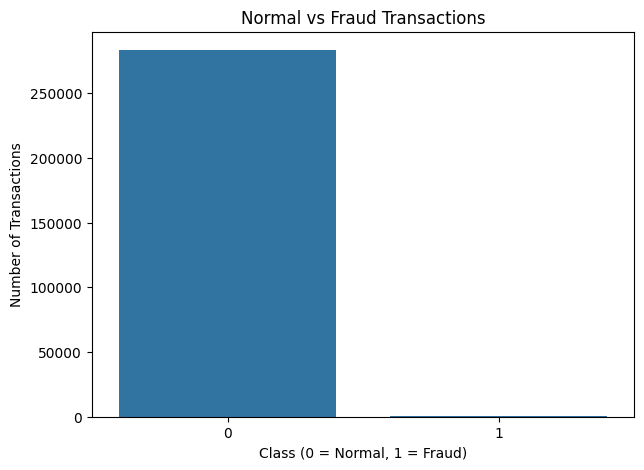

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(x="Class", data=df)

plt.title("Normal vs Fraud Transactions")
plt.xlabel("Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

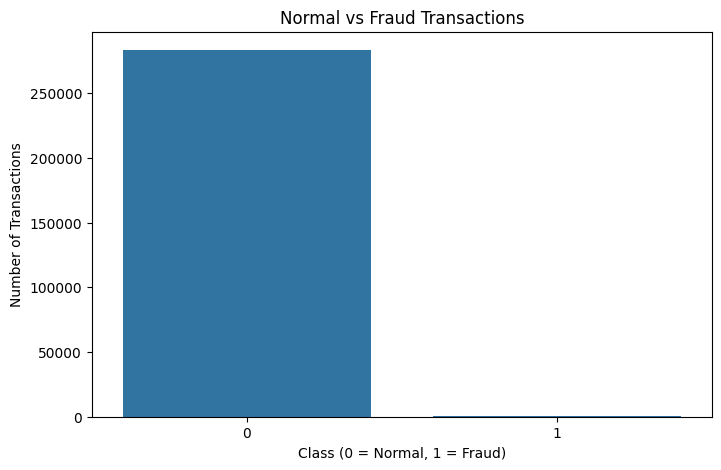

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(x="Class", data=df)

plt.title("Normal vs Fraud Transactions")
plt.xlabel("Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

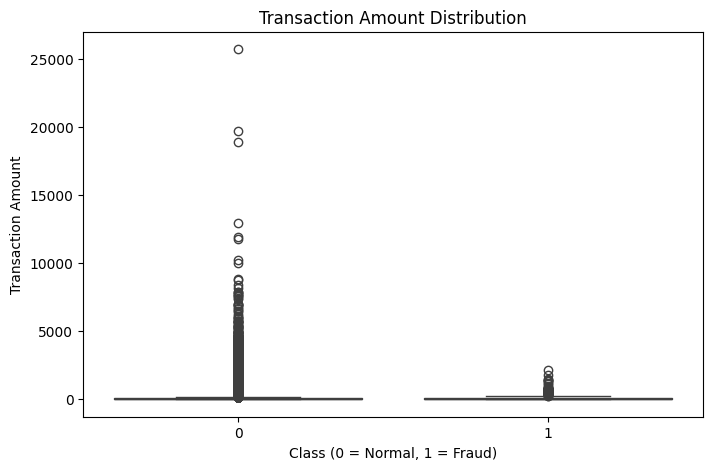

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(x="Class", y="Amount", data=df)

plt.title("Transaction Amount Distribution")
plt.xlabel("Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.show()

In [14]:
print(df.corr()["Class"].sort_values(ascending=False))

Class     1.000000
V11       0.149067
V4        0.129326
V2        0.084624
V19       0.033631
V8        0.033068
V21       0.026357
V27       0.021892
V20       0.021486
V28       0.009682
Amount    0.005777
V22       0.004887
V26       0.004265
V25       0.003202
V15      -0.003300
V13      -0.003897
V23      -0.006333
V24      -0.007210
Time     -0.012359
V6       -0.043915
V5       -0.087812
V9       -0.094021
V1       -0.094486
V18      -0.105340
V7       -0.172347
V3       -0.182322
V16      -0.187186
V10      -0.206971
V12      -0.250711
V14      -0.293375
V17      -0.313498
Name: Class, dtype: float64


In [15]:
# Separate input features
X = df.drop("Class", axis=1)

# Separate target column
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (226980, 30)
Testing data: (56746, 30)


In [19]:
print("Training data distribution:")
print(y_train.value_counts())

print("\nTesting data distribution:")
print(y_test.value_counts())

Training data distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing data distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [22]:
# Create the scaler
scaler = StandardScaler()

# Learn scaling values from training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to testing data
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (226980, 30)
Testing data shape: (56746, 30)


In [25]:
# Create Logistic Regression model
model_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
model_lr.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [26]:
# Make predictions on testing data
y_pred_lr = model_lr.predict(X_test_scaled)

print("Predictions completed successfully!")
print("Total predictions:", len(y_pred_lr))

Predictions completed successfully!
Total predictions: 56746


In [27]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred_lr)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 97.53110351390406 %


In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred_lr)
recall = recall_score(y_test, y_pred_lr)
f1 = f1_score(y_test, y_pred_lr)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.05638586956521739
Recall: 0.8736842105263158
F1 Score: 0.10593490746649649


In [29]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

print(cm)

[[55262  1389]
 [   12    83]]


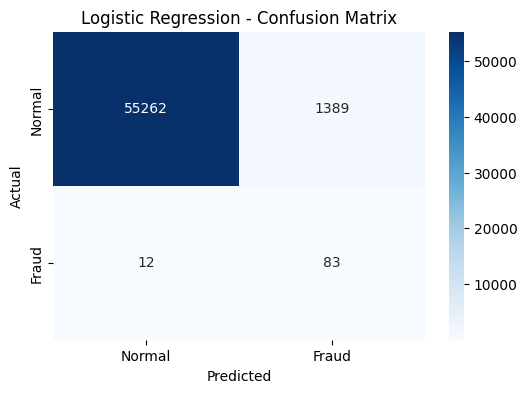

In [30]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [31]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Normal", "Fraud"]
))

              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



In [34]:
# Create Random Forest model
model_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Train the model
model_rf.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [35]:
# Make predictions using Random Forest
y_pred_rf = model_rf.predict(X_test)

print("Random Forest predictions completed!")
print("Total predictions:", len(y_pred_rf))

Random Forest predictions completed!
Total predictions: 56746


In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf * 100, "%")
print("Random Forest Precision:", precision_rf)
print("Random Forest Recall:", recall_rf)
print("Random Forest F1 Score:", f1_rf)

Random Forest Accuracy: 99.94713283755684 %
Random Forest Precision: 0.9710144927536232
Random Forest Recall: 0.7052631578947368
Random Forest F1 Score: 0.8170731707317073


In [37]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

[[56649     2]
 [   28    67]]


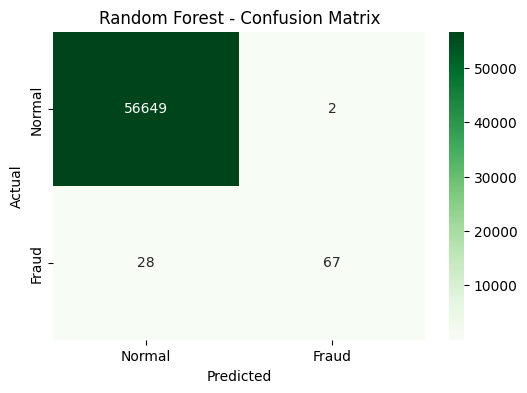

In [38]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [39]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, accuracy_rf],
    "Precision": [precision, precision_rf],
    "Recall": [recall, recall_rf],
    "F1 Score": [f1, f1_rf]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.975311   0.056386  0.873684  0.105935
1        Random Forest  0.999471   0.971014  0.705263  0.817073


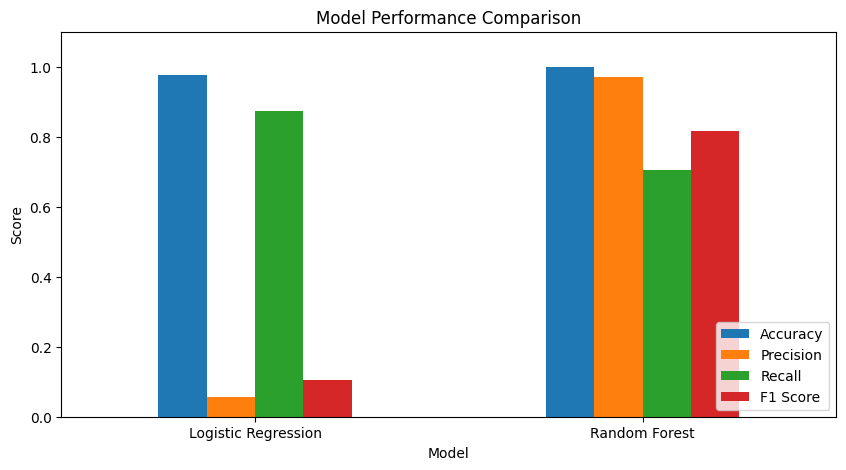

In [40]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

In [41]:
# Get fraud probabilities from Random Forest
y_prob_rf = model_rf.predict_proba(X_test)[:, 1]

# Display first 10 probabilities
print(y_prob_rf[:10])

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [42]:
print("Minimum probability:", y_prob_rf.min())
print("Maximum probability:", y_prob_rf.max())

print("\nFraud probability statistics:")
print(pd.Series(y_prob_rf).describe())

Minimum probability: 0.0
Maximum probability: 1.0

Fraud probability statistics:
count    56746.000000
mean         0.001395
std          0.030953
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
dtype: float64


In [43]:
# Set a new threshold
threshold = 0.2

# Convert probabilities into predictions
y_pred_rf_02 = (y_prob_rf >= threshold).astype(int)

# Calculate metrics
print("Precision:", precision_score(y_test, y_pred_rf_02))
print("Recall:", recall_score(y_test, y_pred_rf_02))
print("F1 Score:", f1_score(y_test, y_pred_rf_02))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_02))

Precision: 0.9259259259259259
Recall: 0.7894736842105263
F1 Score: 0.8522727272727273

Confusion Matrix:
[[56645     6]
 [   20    75]]


In [44]:
from sklearn.metrics import average_precision_score

ap_score = average_precision_score(y_test, y_prob_rf)

print("Random Forest Average Precision:", ap_score)

Random Forest Average Precision: 0.7977673337490048


In [45]:
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("New Training data:", X_train_new.shape)
print("Validation data:", X_val.shape)

New Training data: (181584, 30)
Validation data: (45396, 30)


In [46]:
model_rf_val = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

model_rf_val.fit(X_train_new, y_train_new)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [47]:
y_val_prob = model_rf_val.predict_proba(X_val)[:, 1]

print(y_val_prob[:10])

[0.   0.   0.   0.   0.   0.   0.   0.   0.   0.01]


In [48]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred, zero_division=0)
    recall = recall_score(y_val, y_val_pred, zero_division=0)
    f1 = f1_score(y_val, y_val_pred, zero_division=0)

    print("Threshold:", threshold)
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("----------------------")

Threshold: 0.1
Precision: 0.8571
Recall: 0.8684
F1 Score: 0.8627
----------------------
Threshold: 0.2
Precision: 0.942
Recall: 0.8553
F1 Score: 0.8966
----------------------
Threshold: 0.3
Precision: 0.942
Recall: 0.8553
F1 Score: 0.8966
----------------------
Threshold: 0.4
Precision: 0.9552
Recall: 0.8421
F1 Score: 0.8951
----------------------
Threshold: 0.5
Precision: 0.9836
Recall: 0.7895
F1 Score: 0.8759
----------------------


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score,
    classification_report
)

# Predict fraud probabilities on test data
y_test_prob = model_rf_val.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_test_pred_final = (y_test_prob >= 0.2).astype(int)

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_test_pred_final))
print("Precision:", precision_score(y_test, y_test_pred_final))
print("Recall:", recall_score(y_test, y_test_pred_final))
print("F1 Score:", f1_score(y_test, y_test_pred_final))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_final))

print("\nAverage Precision:")
print(average_precision_score(y_test, y_test_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_final))

Accuracy: 0.9995418179254926
Precision: 0.9367088607594937
Recall: 0.7789473684210526
F1 Score: 0.8505747126436781

Confusion Matrix:
[[56646     5]
 [   21    74]]

Average Precision:
0.8083811341086631

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.94      0.78      0.85        95

    accuracy                           1.00     56746
   macro avg       0.97      0.89      0.93     56746
weighted avg       1.00      1.00      1.00     56746



In [50]:
from sklearn.metrics import average_precision_score

print("Logistic Regression:")
print("Average Precision:",
      average_precision_score(y_test, model_lr.predict_proba(X_test_scaled)[:, 1]))

print("\nRandom Forest:")
print("Average Precision:",
      average_precision_score(y_test, y_test_prob))

Logistic Regression:
Average Precision: 0.6719244530518994

Random Forest:
Average Precision: 0.8083811341086631


In [51]:
import joblib

joblib.dump(model_rf_val, "credit_card_fraud_model.pkl")

print("Model saved successfully!")

Model saved successfully!
